# 호텔 예약 취소 예측: 데이터 확인
1. 범주형을 정수로 바꿔 상관계수 보기
2. 이상치 확인하기
3. 이상치 제거

### 0. 준비
아래 셀을 실행하면 파일 선택 창이 뜹니다. `hotel_bookings.csv`를 올려주세요.
(구글 드라이브에 있다면 두 번째 셀의 주석을 풀고 경로를 바꿔 쓰세요.)

In [32]:
!pip install -q koreanize-matplotlib

In [33]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns
import koreanize_matplotlib
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import confusion_matrix
from sklearn.tree import plot_tree
from scipy.stats import uniform, randint
from sklearn.model_selection import RandomizedSearchCV

In [34]:
from google.colab import drive
drive.mount('/content/drive')

url = "/content/drive/MyDrive/Colab Notebooks/bigdata/"
df = pd.read_csv(url+"hotel_bookings.csv")

df.sample(10)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


,hotel,lead_time,arrival_month,adults,children,babies,country,market_segment,deposit_type,customer_type,adr,previous_cancellations,special_requests,is_canceled
403,Resort Hotel,216,Feb,2,0.0,0,FRA,Agent,No Deposit,Contract,213.0,4,3,1
208,City Hotel,92,Jan,2,1.0,0,KOR,Online,No Deposit,Group,88.0,5,2,1
9,City Hotel,1200,Apr,2,0.0,0,CHN,Online,Refundable,Contract,271.0,3,0,1
280,City Hotel,252,Aug,2,0.0,0,JPN,Online,No Deposit,Transient,102.0,2,4,1
70,City Hotel,141,Jan,2,0.0,0,KOR,Agent,No Deposit,Transient,52.0,2,4,1
268,Resort Hotel,121,Aug,2,0.0,0,CHN,Offline,Refundable,Contract,NaN,4,1,0
201,City Hotel,252,Oct,2,2.0,0,KOR,Corporate,Non Refund,Group,105.0,4,4,1
154,Resort Hotel,203,May,2,0.0,0,FRA,Offline,Refundable,Group,193.0,3,0,1
431,City Hotel,347,Jan,3,0.0,0,GBR,Corporate,Refundable,Transient,299.0,0,4,0
89,City Hotel,169,Jun,2,1.0,0,KOR,Offline,No Deposit,Transient,232.0,0,0,1


In [ ]:
df['is_canceled'] = df['is_canceled'].map({'0': 0, '1': 1})

In [35]:
df.info()   # 자료형과 결측치 확인

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 457 entries, 0 to 456
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   hotel                   457 non-null    object 
 1   lead_time               457 non-null    int64  
 2   arrival_month           457 non-null    object 
 3   adults                  457 non-null    int64  
 4   children                449 non-null    float64
 5   babies                  457 non-null    int64  
 6   country                 450 non-null    object 
 7   market_segment          457 non-null    object 
 8   deposit_type            453 non-null    object 
 9   customer_type           457 non-null    object 
 10  adr                     452 non-null    float64
 11  previous_cancellations  457 non-null    int64  
 12  special_requests        457 non-null    int64  
 13  is_canceled             457 non-null    int64  
dtypes: float64(2), int64(6), object(6)
memory 

## 1. 범주형을 정수로 바꿔 상관계수 보기
- 월은 순서가 있으니 직접 1~12로 바꿉니다.
- 나머지 범주형은 알파벳 순서대로 0, 1, 2 … 번호가 붙습니다. 빈 칸은 -1이 됩니다.

In [36]:
data = df.copy()          # 원본은 그대로 두고 복사본으로 작업

# 1) 월은 순서가 있으니 직접 숫자로
month = {'Jan': 1, 'Feb': 2, 'Mar': 3, 'Apr': 4, 'May': 5, 'Jun': 6,
         'Jul': 7, 'Aug': 8, 'Sep': 9, 'Oct': 10, 'Nov': 11, 'Dec': 12}
data['arrival_month'] = data['arrival_month'].map(month)

# 2) 나머지 범주형은 0, 1, 2 ... 로 자동 변환
cat_cols = ['hotel', 'country', 'market_segment', 'deposit_type', 'customer_type']
for col in cat_cols:
    data[col] = data[col].astype('category')
    print(col, dict(enumerate(data[col].cat.categories)))   # 어떤 숫자가 무슨 값인지
    data[col] = data[col].cat.codes

data.head()

hotel {0: 'City Hotel', 1: 'Resort Hotel'}
country {0: 'CHN', 1: 'FRA', 2: 'GBR', 3: 'JPN', 4: 'KOR', 5: 'USA'}
market_segment {0: 'Agent', 1: 'Corporate', 2: 'Offline', 3: 'Online'}
deposit_type {0: 'No Deposit', 1: 'Non Refund', 2: 'Refundable'}
customer_type {0: 'Contract', 1: 'Group', 2: 'Transient'}


,hotel,lead_time,arrival_month,adults,children,babies,country,market_segment,deposit_type,customer_type,adr,previous_cancellations,special_requests,is_canceled
0,1,263,12,2,0.0,0,4,3,2,2,227.0,0,1,0
1,0,282,2,2,0.0,0,2,0,0,0,328.0,1,2,1
2,1,26,6,2,1.0,0,1,1,2,1,195.0,5,2,1
3,1,225,2,2,0.0,0,1,2,0,1,1500.0,2,4,1
4,1,276,2,2,2.0,0,4,1,0,1,111.0,1,2,1


In [37]:
# 3) 취소여부(is_canceled)와의 상관계수만 정렬
corr = data.corr()
corr['is_canceled'].sort_values(ascending=False).round(2)

,is_canceled
is_canceled,1.00
previous_cancellations,0.38
lead_time,0.25
customer_type,0.05
country,0.03
adr,0.01
children,-0.02
adults,-0.04
babies,-0.04
market_segment,-0.05


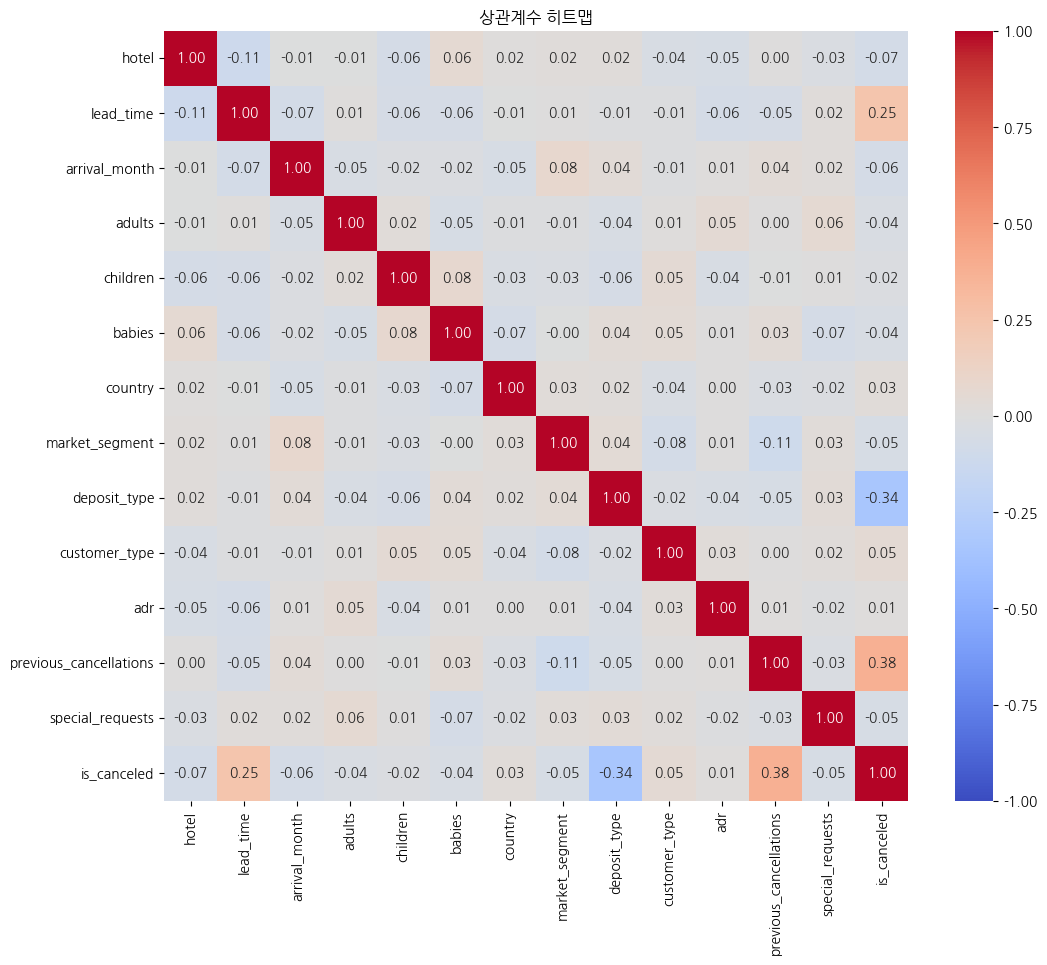

In [38]:
# 4) 히트맵
plt.figure(figsize=(12, 10))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('상관계수 히트맵')
plt.show()

**해석 시 주의**
- 정수 번호에는 크기 의미가 없어서 관계가 왜곡될 수 있습니다.
  - 예: customer_type은 0.05로 나오지만 실제로는 Group의 취소율이 94%입니다.
- 그래서 이 결과는 훑어보기용으로만 쓰세요.
- 모델에 넣을 때는 이렇게 하면 됩니다.
  - 트리 모델(결정트리, 랜덤포레스트): 정수 그대로 사용
  - 로지스틱 회귀, KNN: `pd.get_dummies` 원-핫 인코딩

## 2. 이상치 확인하기

In [39]:
num_cols = ['lead_time', 'adults', 'children', 'babies', 'adr',
            'previous_cancellations', 'special_requests']

# 1) 요약 통계: min, max가 상식적인지 확인
df[num_cols].describe()

,lead_time,adults,children,babies,adr,previous_cancellations,special_requests
count,457.000000,457.000000,449.000000,457.000000,452.000000,457.000000,457.000000
mean,181.516411,2.317287,0.389755,0.045952,229.280973,2.595186,2.048140
std,131.235593,1.364488,0.669476,0.209610,270.274359,1.679409,1.385182
min,0.000000,1.000000,0.000000,0.000000,-50.000000,0.000000,0.000000
25%,95.000000,2.000000,0.000000,0.000000,143.000000,1.000000,1.000000
50%,176.000000,2.000000,0.000000,0.000000,225.000000,3.000000,2.000000
75%,258.000000,3.000000,1.000000,0.000000,281.250000,4.000000,3.000000
max,1500.000000,20.000000,2.000000,1.000000,5000.000000,5.000000,4.000000


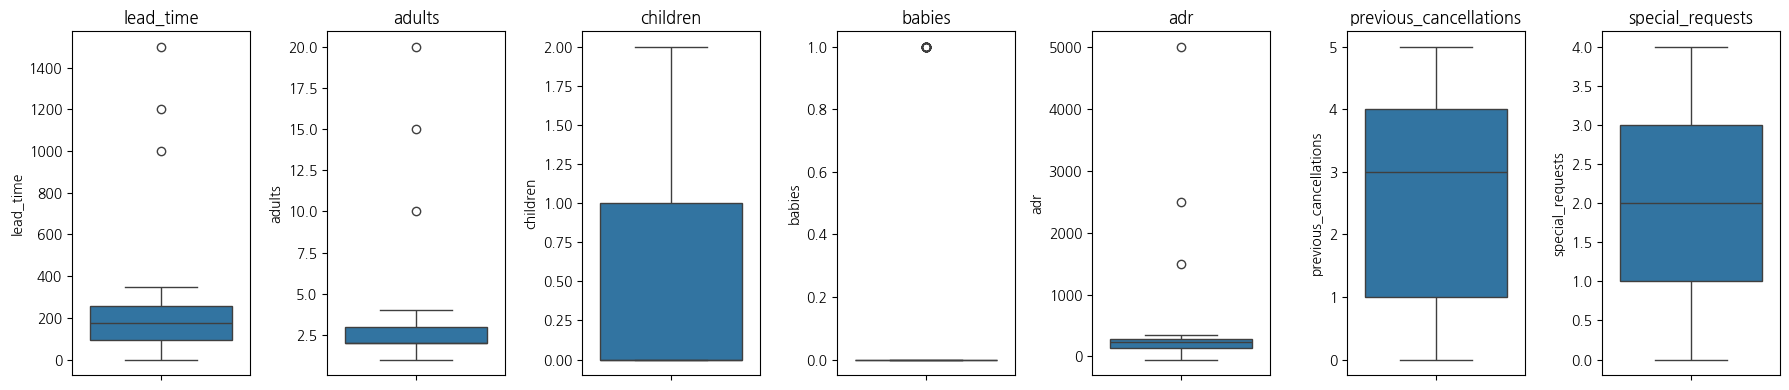

In [40]:
# 2) 박스플롯: 상자 밖으로 튀어나온 점이 이상치 후보
fig, axes = plt.subplots(1, 7, figsize=(18, 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

In [41]:
# 3) IQR 방법으로 이상치 개수와 값 출력
for col in num_cols:
    Q1 = df[col].quantile(0.25)          # 하위 25%
    Q3 = df[col].quantile(0.75)          # 상위 25%
    IQR = Q3 - Q1
    low, high = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
    out = df[(df[col] < low) | (df[col] > high)][col]
    print(f'{col}: 정상범위 {low:.0f} ~ {high:.0f}, 이상치 {len(out)}개 → {sorted(out.tolist())}')

lead_time: 정상범위 -150 ~ 502, 이상치 3개 → [999, 1200, 1500]
adults: 정상범위 0 ~ 4, 이상치 3개 → [10, 15, 20]
children: 정상범위 -2 ~ 2, 이상치 0개 → []
babies: 정상범위 0 ~ 0, 이상치 21개 → [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
adr: 정상범위 -64 ~ 489, 이상치 3개 → [1500.0, 2500.0, 5000.0]
previous_cancellations: 정상범위 -4 ~ 8, 이상치 0개 → []
special_requests: 정상범위 -2 ~ 6, 이상치 0개 → []


**IQR 결과를 그대로 믿으면 안 되는 경우**
- babies 21개는 정상 값입니다. 대부분이 0이라서 아기 1명인 예약까지 이상치로 잡힌 겁니다.
- adr = -50(음수 요금)은 IQR 정상범위 안이라 못 잡습니다. 상식으로 따로 걸러야 합니다.

## 3. 이상치 제거

In [43]:
"""print('제거 전:', len(df))
df_clean = df[(df['lead_time'] <= 365) &
              (df['adults'] <= 6) &
              (df['adr'].between(0, 1000) | df['adr'].isna())]
print('제거 후:', len(df_clean))

_IncompleteInputError: incomplete input (2799834333.py, line 1)

In [45]:
X = df.drop(columns=["previous_cancellations","lead_time","hotel",'deposit_type',"arrival_month"])
y = df["is_canceled"]

In [47]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y)